# Week 9 · Big data and web scraping

**CMT309/509 · CMT124** · shared session · Thursday 3 December 2026

So far every dataset has been a tidy file that fits comfortably in memory. Today we look at both ends of that assumption: what changes when the data is **too big** for pandas alone, and how to get data that isn't a file at all because it sits on a **web page**.

By the end of today you can explain the 5Vs and the big-data pipeline, process a multi-million-row file with **Dask**, store tables as **Parquet**, download a page responsibly, and turn an HTML table into a pandas DataFrame with **BeautifulSoup**.

Today has three teaching parts and a lab: **Hour 1** when data stops fitting · **Hour 2** getting data from the web · **Hour 3** a real table, from Wikipedia to a DataFrame · **Lab** scrape a table and store it efficiently.

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import time
import urllib.request
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dask.dataframe as dd
from bs4 import BeautifulSoup

os.makedirs("w09_output", exist_ok=True)          # files we create today go here (safe to delete)

## Hour 1 · When data stops fitting

### What makes data "big"?

**Big data** means data that is too large, too fast or too messy for the usual tools on one computer. Size is only one part of it. A common way to describe the challenge is the **5Vs**:

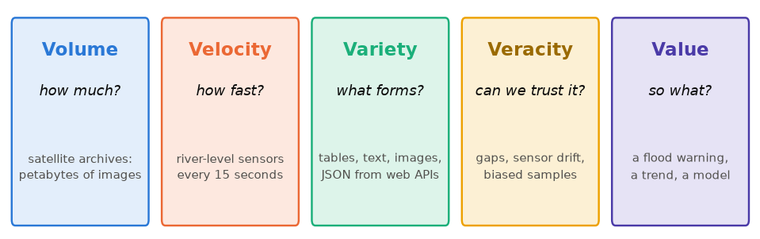

Each V asks for a different kind of tool: **volume** needs distributed storage and processing, **velocity** needs streaming systems, **variety** needs flexible formats, **veracity** needs cleaning and validation, and **value** comes from the analysis, models and dashboards at the end.

### The big-data pipeline

Whatever the size, data travels through the same five stages. The tools change from stage to stage, and they change again as the data grows.

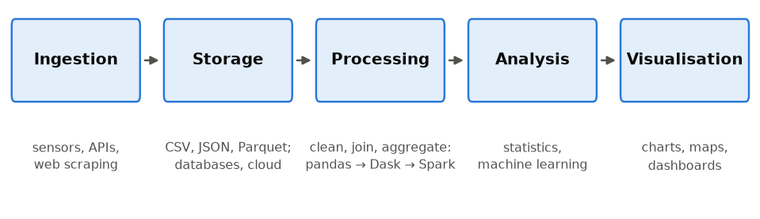

### Batch or stream?

| | **Batch** processing | **Stream** processing |
|---|---|---|
| Works on | a large, finished collection, in chunks | each record as it arrives |
| Speed | minutes to hours is fine | seconds or less |
| Typical use | historical analysis, reports, training models | monitoring, alerts, live dashboards |
| Example tools | pandas, Dask, Spark (batch) | Kafka, Flink, Spark Streaming |

**Discuss:** the Environment Agency receives river-level readings every few minutes. Which approach suits each job, and why? (a) sending a flood alert for a village; (b) estimating how peak river levels have changed over the last 30 years.

<details><summary>Answer</summary>

(a) **Stream**: the value of an alert disappears if it arrives hours late, so each reading is checked as it arrives. (b) **Batch**: the question is about a long, finished record; it can run overnight and must be reproducible. Many real systems do both with the same data.

</details>

### Python that scales

| Tool | Typical data size | Runs on | Idea |
|---|---|---|---|
| **pandas** | fits in memory (up to a few GB) | one machine, one core | the whole table is in RAM |
| **Dask** | bigger than memory (GB to ~100 GB) | one machine (all cores) or a cluster | pandas-like code, split into **partitions** |
| **PySpark** | very large (100 GB and beyond) | a cluster | a distributed engine with its own API |

The rule of thumb: **start small with pandas, and scale only when you need to.** Today we try Dask, because its code looks almost exactly like pandas.

### A file with three million rows

We need a big file to experiment with. The next cell writes a **synthetic** CSV into the folder `w09_output`: three million made-up temperature readings, each with a region and a year.

**Before we run this:** each row looks like `Asia,17.2,2004`. Roughly how many megabytes will three million rows take on disk?

In [ ]:
rng = np.random.default_rng(0)
n = 3_000_000
regions = np.array(["Africa", "Americas", "Asia", "Europe", "Oceania"])
typical = np.array([24.0, 15.0, 17.0, 10.0, 19.0])     # a typical temperature for each region
pick = rng.integers(0, 5, n)
synth = pd.DataFrame({"region": regions[pick],
                      "temperature": (typical[pick] + rng.normal(0, 8, n)).round(2),
                      "year": rng.integers(1990, 2025, n)})
synth.to_csv("w09_output/synthetic_readings.csv", index=False)
print(f"{os.path.getsize('w09_output/synthetic_readings.csv') / 1e6:.0f} MB on disk")

About 50 MB: small for real big data, but large enough to see the ideas. Now the pandas way. `%time` reports how long one line takes.

In [ ]:
%time df = pd.read_csv("w09_output/synthetic_readings.csv")
%time means = df.groupby("region")["temperature"].mean()
print(f"{df.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
means

pandas reads the **whole file** into memory, and the DataFrame takes several times more space in memory than the file on disk (text is stored as Python strings). With a 50 GB file this simply stops working.

### Dask: the same question, in partitions

Dask splits the file into **partitions** (blocks of rows), works on each one separately, possibly in parallel, and combines the partial results at the end. Nothing is calculated until you ask for the result with **`.compute()`**.

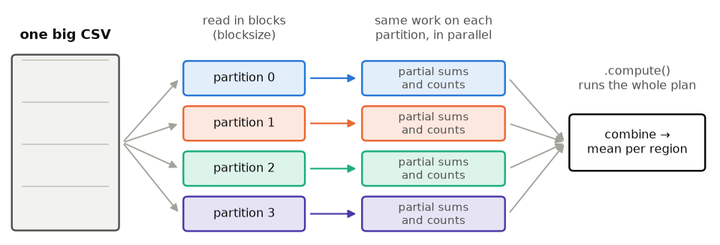

In [ ]:
# ✍️ Type along: read the same CSV with Dask, in 16 MB blocks

<details><summary>Code from class</summary>

```python
ddf = dd.read_csv("w09_output/synthetic_readings.csv", blocksize="16MB")
print(ddf.npartitions, "partitions")
ddf.head()                  # head() only needs the first partition
```

</details>

**Predict:** we now ask Dask for the mean temperature per region, exactly as in pandas. What will `lazy` show: five numbers, or something else?

In [ ]:
ddf = dd.read_csv("w09_output/synthetic_readings.csv", blocksize="16MB")
lazy = ddf.groupby("region")["temperature"].mean()
lazy

No numbers yet. `lazy` is a **plan** (a task graph): it records *what* to compute and the type of the result, but no data has been read. This is called **lazy evaluation**. `.compute()` runs the plan:

In [ ]:
%time result = lazy.compute()
result

The same five means as pandas. On a 50 MB file Dask is not much faster, and it can even be slower: splitting and combining has a cost. Its advantage is that it **never needs the whole file in memory** and it uses every core, so the same code still works on a file of 50 GB.

**Your turn:** read the CSV again with `blocksize="4MB"`. How many partitions do you get now? Compute the mean temperature per region again: does the answer change?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
ddf_small = dd.read_csv("w09_output/synthetic_readings.csv", blocksize="4MB")
print(ddf_small.npartitions)                                     # about 13 partitions
ddf_small.groupby("region")["temperature"].mean().compute()      # the same means
```

More, smaller partitions: more pieces of work that can run in parallel, but also more overhead. The **result** never depends on the blocksize, only the way the work is split.

</details>

### Storage formats: CSV, JSON and Parquet

| Format | What it looks like | Good for | Weak at |
|---|---|---|---|
| **CSV** | plain text, one row per line | small to medium tables; opens anywhere | no types, no compression, slow to parse |
| **JSON** | text with nested `{key: value}` records | web APIs, nested data | bulky, slow for big tables |
| **Parquet** | binary, **column by column**, compressed | big analytical tables (pandas, Dask, Spark) | not human-readable |

Here are two of our rows as JSON records, the format you meet in web APIs:

In [ ]:
print(df.head(2).to_json(orient="records"))

**Parquet** stores each column together and compresses it. It also keeps the data types, so nothing has to be parsed again. And because columns are stored separately, you can read just the columns you need:

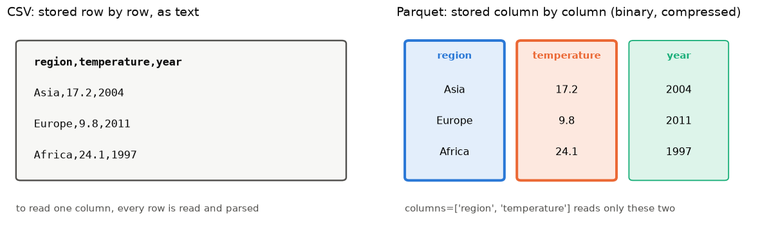

**Predict:** we save the same three million rows as Parquet. Will the file be bigger or smaller than the 50 MB CSV, and will it be faster or slower to read?

In [ ]:
df.to_parquet("w09_output/synthetic_readings.parquet", index=False)
for name in ["w09_output/synthetic_readings.csv", "w09_output/synthetic_readings.parquet"]:
    print(f"{name:38} {os.path.getsize(name) / 1e6:5.1f} MB")
%time back_csv = pd.read_csv("w09_output/synthetic_readings.csv")
%time back_parquet = pd.read_parquet("w09_output/synthetic_readings.parquet")

The Parquet file is several times smaller and faster to read, and `back_parquet.dtypes` already has the right types. On terabytes of data this is the difference between minutes and hours, and between one disk and many.

**Try it:** read **only** the `region` and `year` columns from the Parquet file (use the `columns=` argument of `pd.read_parquet`) and time it. Then count the readings per region.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
%time two = pd.read_parquet("w09_output/synthetic_readings.parquet", columns=["region", "year"])
print(two.shape)                      # (3000000, 2)
two["region"].value_counts()
```

Reading two of the three columns is faster again: Parquet skips the `temperature` column completely. A CSV reader can't skip a column; it has to parse every line.

</details>

### Putting the pipeline together: CO₂ emissions

The same five stages on real data: the Our World in Data CO₂ dataset (about 50,000 rows: one per country or region and year). The first cell runs ingestion, storage, processing and analysis; each stage is one or two lines. Before you look at the result: is the UK among the ten largest emitters?

In [ ]:
raw = pd.read_csv(get_data("owid_co2_w09.csv"))                          # 1 ingestion
raw.to_parquet("w09_output/co2.parquet", index=False)                     # 2 storage
co2 = pd.read_parquet("w09_output/co2.parquet", columns=["country", "iso_code", "year", "co2"])
co2 = co2.dropna(subset=["iso_code", "co2"])                              # 3 processing: countries only
latest = co2[co2["year"] == co2["year"].max()]                            # 4 analysis
top10 = latest.sort_values("co2", ascending=False).head(10)
top10[["country", "year", "co2"]]

Rows without an ISO country code are groups such as *World*, *Asia* or *High-income countries*, so dropping them keeps countries only. Stage 5, visualisation:

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top10["country"], top10["co2"], color="#2a78d6")
ax.invert_yaxis()                                                         # largest at the top
ax.set_xlabel("CO₂ emissions (million tonnes)")
ax.set_title(f"The ten largest CO₂ emitters, {int(top10['year'].max())}")
plt.show()

China emits more than twice as much as the United States, and the UK is not in the top ten. Total emissions are not the whole story: `co2_per_capita` in the same file tells a different one.

*Data: Our World in Data, CO₂ and greenhouse gas emissions (Global Carbon Project), licensed under CC BY 4.0.*

### Takeaways: when data stops fitting

* "Big" is about the **5Vs**, not only size; each V calls for different tools.
* Data moves through **ingestion → storage → processing → analysis → visualisation**, in **batch** or as a **stream**.
* **Dask** runs pandas-like code on **partitions**; it is **lazy** until `.compute()`.
* **Parquet** is smaller, faster, keeps types and lets you read only the columns you need.

## Hour 2 · Getting data from the web

### When the data is on a web page

The first stage of the pipeline is **ingestion**. Sometimes the data comes as a file or through an API. Often it is only on a web page: prices, timetables, tables of statistics. **Web scraping** is the automatic process of downloading pages and extracting structured data from them.

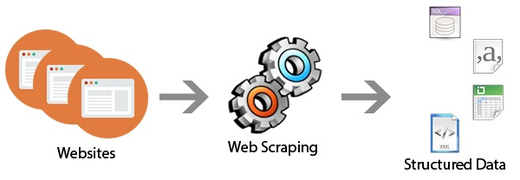

A scraper does four things: **download** the page, **extract** the data, **store** it, **analyse** it. Before writing any code, open the page in a browser and **inspect** it (right-click → *Inspect*) to find where the data sits in the HTML.

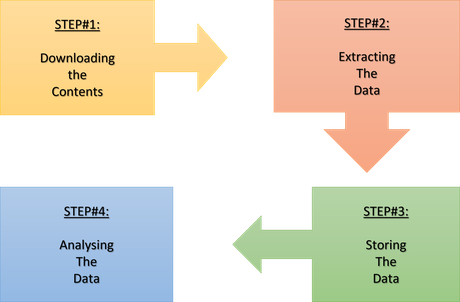

### Scraping responsibly

Being able to download a page does not mean you may scrape it.

| Check | What it means in practice |
|---|---|
| **An API or a download?** | if the site offers one, use it instead of scraping |
| **`robots.txt`** | `https://site/robots.txt` lists the parts of a site that automated programs may and may not visit. Respect it |
| **Terms of use** | some sites forbid scraping or reusing their content; licences such as CC BY-SA set conditions |
| **Rate limits** | one request at a time, a pause between requests (`time.sleep(1)`), save pages instead of downloading them again |
| **Say who you are** | send an honest **User-Agent** header naming your program and a contact, e.g. `"W09-class-exercise/1.0 (Cardiff University; you@example.ac.uk)"`. Don't disguise a script as a web browser |
| **Personal data** | under **UK GDPR**, names, e-mail addresses, photos or profiles are personal data **even when they are public**. Collecting them needs a lawful basis (and, for research, ethics approval). Avoid them unless you really need them |

**Quick check:** which of these is fine for a class project? (a) the price table of a public shop page whose `robots.txt` allows it, fetched once and saved; (b) the names and e-mail addresses of everyone who posted on a forum; (c) the same page downloaded 10,000 times in a loop to "keep it up to date".

<details><summary>Answer</summary>

Only (a). (b) is personal data, covered by UK GDPR however public it looks. (c) overloads the site: download once, save, and re-use the saved copy.

</details>

### A page in the browser is a tree of tags

HTML nests **tags** inside each other: `<html>` holds `<head>` and `<body>`, `<head>` holds `<title>`, and so on. A web page is a **tree**, and scraping means finding the right branch. This is the practice page we use next:

<img alt="The HTML tree of a profile page: html contains head and body; head contains title; body contains center, which contains img, h2 and text" src="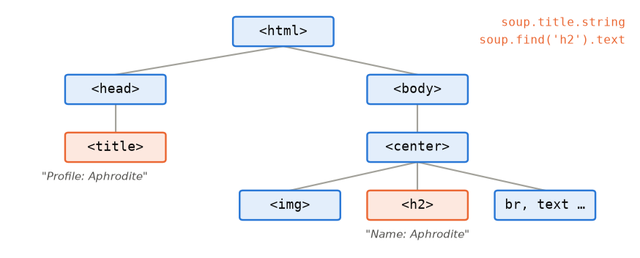">

We use two small practice pages made for scraping exercises. In case the sites are down, run the next cell first: `get_page()` downloads a page with an honest User-Agent and, if the site can't be reached, uses a saved copy instead.

In [ ]:
# @title Run this cell: a polite download helper, with saved copies of the practice pages
USER_AGENT = "W09-class-exercise/1.0 (Cardiff University teaching notebook)"
OLYMPUS = "http://olympus.realpython.org/profiles/"
SHOP = "https://codedamn-classrooms.github.io/webscraper-python-codedamn-classroom-website/"

SAVED = {
    OLYMPUS + "aphrodite": """<html>
<head>
<title>Profile: Aphrodite</title>
</head>
<body bgcolor="yellow">
<center>
<br><br>
<img src="/static/aphrodite.gif" />
<h2>Name: Aphrodite</h2>
<br><br>
Favorite animal: Dove
<br><br>
Favorite color: Red
<br><br>
Hometown: Mount Olympus
</center>
</body>
</html>
""",
    OLYMPUS + "dionysus": """<html>
<head>
<TITLE >Profile: Dionysus</title  / >
</head>
<body bgcolor="yellow">
<center>
<br><br>
<img src="/static/dionysus.jpg" />
<h2>Name: Dionysus</h2>
<img src="/static/grapes.png"><br><br>
Hometown: Mount Olympus
<br><br>
Favorite animal: Leopard <br>
<br>
Favorite Color: Wine
</center>
</body>
</html>
""",
    SHOP: """<html><head><title>codedamn Web Scraper demo</title></head><body>
<div class="thumbnail"><div class="caption"><h4 class="pull-right price">$1139.54</h4>
<h4><a class="title" title="Asus AsusPro Advanced BU401LA-FA271G Dark Grey">Asus AsusPro Adv...</a></h4></div>
<div class="ratings"><p class="pull-right">7 reviews</p><p data-rating="3"></p></div></div>
<div class="thumbnail"><div class="caption"><h4 class="pull-right price">$1101.83</h4>
<h4><a class="title" title="Asus ROG Strix GL553VD-DM535T">Asus ROG Strix G...</a></h4></div>
<div class="ratings"><p class="pull-right">4 reviews</p><p data-rating="2"></p></div></div>
<div class="thumbnail"><div class="caption"><h4 class="pull-right price">$494.71</h4>
<h4><a class="title" title="Acer Aspire 3 A315-51 Black">Acer Aspire 3 A3...</a></h4></div>
<div class="ratings"><p class="pull-right">2 reviews</p><p data-rating="4"></p></div></div>
</body></html>
""",
}


def get_page(url):
    """Download a page with an honest User-Agent; use the saved copy if the site can't be reached."""
    try:
        request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
        with urlopen(request, timeout=10) as response:
            return response.read().decode("utf-8")
    except OSError as err:                # no network, site down, timeout, HTTP error
        print(f"Could not reach {url} ({err}): using the saved copy.")
        return SAVED.get(url, "")

### Step 1 and 2 with the standard library: `urllib` and string methods

`urlopen(url)` downloads a page and `.read()` returns its raw **bytes**; `.decode("utf-8")` turns them into text. Then `str.find()` tells us where `<title>` starts and ends, and a slice cuts out the title.

In [ ]:
# ✍️ Type along: download a profile page and cut out its title with string methods
url = "http://olympus.realpython.org/profiles/aphrodite"

<details><summary>Code from class</summary>

```python
url = "http://olympus.realpython.org/profiles/aphrodite"
page = urlopen(url)                           # urllib's own User-Agent says "Python-urllib"
html = page.read().decode("utf-8")
print(html)

start = html.find("<title>") + len("<title>")
end = html.find("</title>")
html[start:end]                               # 'Profile: Aphrodite'
```

</details>

**Before we run this:** the same slicing code on a second profile page. Will it still find the title?

In [ ]:
html2 = get_page(OLYMPUS + "dionysus")
start = html2.find("<title>") + len("<title>")
end = html2.find("</title>")
html2[start:end]

Rubbish. Look at the page's HTML: the tag is written `<TITLE >` and closed with `</title  / >`. Browsers don't mind, but `find("<title>")` returns `-1` (not found), so the slice starts and ends in the wrong places. **String methods break as soon as the HTML is written slightly differently.**

In [ ]:
print(html2)

### Step 2 with a parser: BeautifulSoup

`BeautifulSoup(html, "html.parser")` reads the HTML the way a browser does and builds the **tree**. Then we ask for tags by name instead of counting characters:

| Code | Returns |
|---|---|
| `soup.title` / `soup.find("h2")` | the first `<title>` / `<h2>` tag |
| `soup.find_all("img")` | a list of every `<img>` tag |
| `tag.text`, `tag.string` | the text inside a tag |
| `tag["src"]` | the value of an attribute |
| `soup.select("div.price")` | tags matching a CSS selector (here: `<div class="price">`) |

**Predict:** will `soup.title.string` find the title on this messy page?

In [ ]:
soup = BeautifulSoup(html2, "html.parser")
print(soup.title.string)
print(soup.find("h2").text)
print([img["src"] for img in soup.find_all("img")])

Yes: the parser understands `<TITLE >` and `</title  / >`, and gives us the heading and both image links as well. Parse HTML with a parser, not with string slicing.

### From a shop page to a CSV file

A practice shop page lists products. Inspecting it shows that each product sits in a `<div class="thumbnail">`, with the price in `<h4 class="price">` and the full name in the `title` attribute of a link. `select_one()` returns the first match inside a product.

In [ ]:
shop_html = get_page(SHOP)
products = BeautifulSoup(shop_html, "html.parser").select("div.thumbnail")
print(len(products), "products")
print(products[0].select_one("h4.price").text.strip())

Now steps 2, 3 and 4 in one go: **extract** one dictionary per product, **store** the list as a CSV file, and read it back for **analysis**.

In [ ]:
records = []
for product in products:
    records.append({"name": product.select_one("h4 > a")["title"],
                    "price": product.select_one("h4.price").text.strip(),
                    "reviews": product.select_one("div.ratings p").text.strip()})
pd.DataFrame(records).to_csv("w09_output/products.csv", index=False)
shop = pd.read_csv("w09_output/products.csv")
shop

A list of dictionaries becomes a DataFrame with one row per product. But the prices are text such as `'$1139.54'`, not numbers.

**Your turn:** compute the **mean price** of the products. You'll need to remove the `$` and convert the column to `float`.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
shop["price_usd"] = shop["price"].str.replace("$", "").astype(float)
shop["price_usd"].mean()                      # about 912.03
```

Scraped values are almost always **text**: cleaning them into numbers is part of every scraping job. Note the units too: these prices are in dollars.

</details>

**Try it:** use `get_page()` to download `https://en.wikipedia.org/robots.txt` and print the first 1,500 characters. Then search the full text for `User-agent: *`: which paths may *every* program not visit?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
robots = get_page("https://en.wikipedia.org/robots.txt")
print(robots[:1500])
start = robots.find("User-agent: *")
print(robots[start:start + 400])
```

The file opens with a warning that misbehaving programs may be blocked, then bans some named bots completely (`Disallow: /`). Under `User-agent: *` it disallows `/w/` (the editing and history pages) and `/wiki/Special:` pages; ordinary article pages under `/wiki/` are allowed. Wikipedia also refuses (HTTP 403) requests from scripts that don't say who they are, including `urlopen()` with its default User-Agent. That is why `get_page()` sends one.

</details>

### Takeaways: getting data from the web

* Scraping = **download → extract → store → analyse**; inspect the page first.
* Check for an API, `robots.txt` and the terms of use; go slowly; send an honest **User-Agent**; avoid **personal data** (UK GDPR).
* String slicing works only on perfectly regular HTML; **BeautifulSoup** parses the tree: `find`, `find_all`, `select`, `.text`, `["attr"]`.
* Scraped values arrive as **text**: clean and convert them before analysis.

## Hour 3 · A real table: from Wikipedia to a DataFrame

### How an HTML table is built

Tables on real pages are where scraping pays off. An HTML table is a `<table>` made of **rows** (`<tr>`); each row holds **header cells** (`<th>`) or **data cells** (`<td>`):

```html
<table class="wikitable">
  <tr> <th>Species</th>          <th>Common name</th> <th>Type</th>         </tr>
  <tr> <td>Abies beshanzuensis</td> <td>Baishan fir</td> <td>Plant (Tree)</td> </tr>
</table>
```

So the recipe is: find the table → find its rows → in each row, find the cells → take their text.

Our page is Wikipedia's list of *The world's 100 most threatened species*. Pages like this change every week, so we work on a **saved snapshot** of the page from 28 April 2025: the row numbers below will always match. (Downloading the live page is a lab challenge.)

In [ ]:
html = open(get_data("wiki_100_most_threatened_species_2025-04-28.html"), encoding="utf-8").read()
soup = BeautifulSoup(html, "html.parser")
rows = soup.find_all("tr")
len(rows)

**Quick check:** the table has one header row and (about) 100 species. Why does `find_all("tr")` find 117 rows?

<details><summary>Answer</summary>

The page has **more than one table**: the navigation boxes at the bottom of every Wikipedia page are tables too. Searching the whole page mixes their rows in. Always check what you found before you index into it.

</details>

Better: find the **species table** first (it has the class `wikitable`), then search for rows only inside it.

In [ ]:
print(len(soup.find_all("table")), "tables on the page")
table = soup.find("table", class_="wikitable")
rows = table.find_all("tr")
print(len(rows), "rows in the species table")
[th.text.strip() for th in rows[0].find_all("th")]

One header row and 101 species rows: real data rarely matches its title exactly. Now one data row, step by step.

In [ ]:
# ✍️ Type along: take one row apart
row = rows[68]

<details><summary>Code from class</summary>

```python
row = rows[68]
cells = row.find_all("td")
print(len(cells))                              # 7 cells, one per column
texts = [cell.text.strip() for cell in cells]
texts

texts[2].split(" (")[0]                        # 'Fish': the group, without '(…)'
cells[3].find("a")["href"]                     # the link to the image page
```

</details>

For the **Image** column the text is empty: the cell holds a link to the picture. (We keep the link, not the image: images on Wikipedia have their own licences.) A first idea is to cut the link out of the cell's HTML with string methods, as in Hour 2.

**Predict:** the next cell works for row 68. Why does `str(cells[3]).split('href=')[1]` fail for row 15?

In [ ]:
# ⚠️ This cell raises an error on purpose
cells = rows[15].find_all("td")
print([cell.text.strip()[:25] for cell in cells])
str(cells[3]).split('href=')[1]

Row 15 has **no image**: its Image cell is empty, so there is no `href=` to split on. `split()` returns a list with just one item, and `[1]` raises an `IndexError`. Real tables are **irregular**: some cells are empty, some hold a link, some have extra notes. **Check before you index:**

In [ ]:
link = cells[3].find("a")                      # None if the cell has no link
if link is None:
    image = "No image"
else:
    image = link["href"]
image

### The whole table

The full loop does for every row what we just did for one: take the cell texts, keep the group from the Type column, check for an image link, and collect one dictionary per species. `pd.DataFrame()` turns the list of dictionaries into a table.

In [ ]:
records = []
for row in rows[1:]:                           # rows[0] is the header
    cells = row.find_all("td")
    texts = [cell.text.strip() for cell in cells]
    link = cells[3].find("a")
    records.append({"species": texts[0], "common_name": texts[1],
                    "group": texts[2].split(" (")[0],
                    "image": link["href"] if link is not None else "No image",
                    "location": texts[4], "population": texts[5], "threats": texts[6]})
species = pd.DataFrame(records)
print(species.shape)
species[["species", "common_name", "group", "population"]].head(3)

`x if condition else y` is a one-line `if`/`else`: it does the same as the four-line check above. With a DataFrame, pandas does the rest:

In [ ]:
species["group"].value_counts().head(6)

Plants and mammals dominate the list. The **Threats** column still needs work: each threat was a list item on the page, so the text holds several threats separated by `"\n"` (new line).

**Your turn:** clean the `threats` column. (1) Replace each `"\n"` with `"; "`. (2) Add a column `n_threats` with the number of threats for each species. (3) Which species has the most threats listed?

In [ ]:
species["threats"].head(3).tolist()
# your code here

<details><summary>Answer</summary>

```python
species["threats"] = species["threats"].str.replace("\n", "; ")
species["n_threats"] = species["threats"].str.count("; ") + 1
species.sort_values("n_threats", ascending=False)[["species", "n_threats", "threats"]].head(3)
```

Most species list one or two threats; a few list four. (`.str.split("; ").str.len()` counts them too.) The pandas `.str` methods from Week 8 do the cleaning for the whole column at once.

</details>

*Data: Wikipedia contributors, "The world's 100 most threatened species" (revision of 28 April 2025), licensed under CC BY-SA 4.0.*

### Takeaways: a real table

* Find the **table** first (`find("table", class_=...)`), then its rows (`tr`), then the cells (`th`, `td`).
* Real rows are **irregular**: check that a tag exists (`is None`) before you index into it.
* One dictionary per row → a list → `pd.DataFrame()`; then clean with the `.str` methods.
* Work on a **saved snapshot** so your code and your results stay reproducible.

## Transition to the lab

**You now know** why big data needs different tools (Dask, Parquet), how to download a page responsibly, and how to turn an HTML table into a DataFrame with BeautifulSoup.

**The lab** (`W09_lab_student.ipynb`, one hour) puts the whole pipeline together on a second Wikipedia snapshot, *List of countries by population growth rate*: find the table, build the column names, scrape every row into a DataFrame, store it as **CSV and Parquet** and compare the two, then draw the ten fastest-growing countries. An optional challenge compares the snapshot with today's live page.

## Week 9 takeaways

* The **5Vs** and the **pipeline** (ingestion → storage → processing → analysis → visualisation) describe any data project; batch and stream are two ways to run it.
* **Start small, scale when needed:** pandas → Dask (partitions, lazy, `.compute()`) → Spark.
* **Parquet** is the format for big analytical tables; CSV and JSON are for exchange.
* **Scrape responsibly:** API first, `robots.txt`, terms, slow requests, honest User-Agent, no personal data.
* **BeautifulSoup** turns HTML into a tree; tables become DataFrames row by row, checking before indexing.

## Where next

**Week 10 · Statistics for data science.** You can now collect and store data at scale. Next week asks what the data can tell you, and how sure you can be: probability, distributions, confidence intervals and hypothesis tests, again on the CO₂ data.

Before next week: reopen this notebook, run it top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

**PySpark.** Spark is the standard engine for data spread over a cluster of machines. The same question as today looks like this in PySpark (Spark needs Java; in Colab, `pip install pyspark` first). Try it on `synthetic_readings.csv` if you are curious; it is not needed later in the module.

```python
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("W09").getOrCreate()
sdf = spark.read.csv("w09_output/synthetic_readings.csv", header=True, inferSchema=True)
sdf.groupBy("region").avg("temperature").show()
spark.stop()
```

**Other formats you will meet:** **Feather** (fast binary, for passing tables between programs), **HDF5** (large numeric arrays), **Pickle** (any Python object; never open a pickle from a source you don't trust: loading it can run code).

**Checking `robots.txt` in code.** The standard library can read a `robots.txt` file and answer "may I fetch this URL?":

In [ ]:
from urllib import robotparser
rules = robotparser.RobotFileParser()
rules.parse(get_page("https://en.wikipedia.org/robots.txt").splitlines())
print(rules.can_fetch(USER_AGENT, "https://en.wikipedia.org/wiki/Dask"))
print(rules.can_fetch(USER_AGENT, "https://en.wikipedia.org/wiki/Special:Random"))

## Credits

Data: Our World in Data, CO₂ dataset (Global Carbon Project), CC BY 4.0 · Wikipedia contributors, *The world's 100 most threatened species* (revision of 28 April 2025), CC BY-SA 4.0 · practice pages: Real Python's *olympus* profiles and the codedamn web-scraper classroom site.